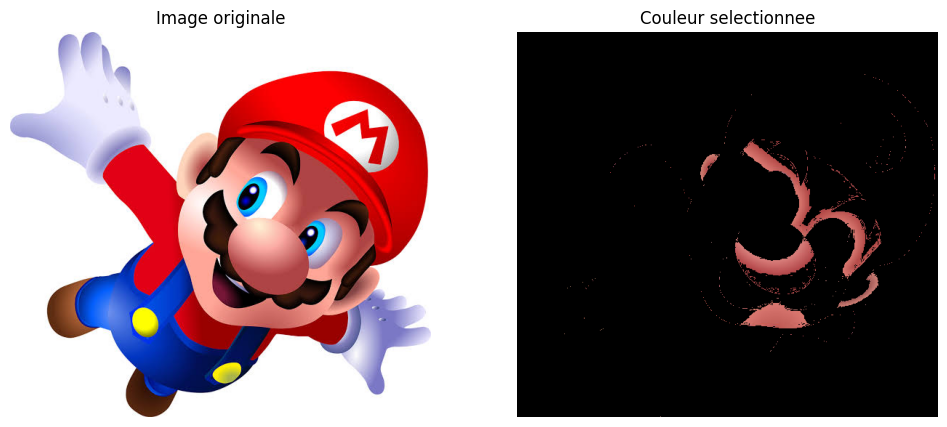

True

In [7]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Charger l'image
image = cv2.imread("image.png")

if image is None:
    raise FileNotFoundError("Image introuvable")

# Selectionner un rectangle avec la souris
x, y, w, h = cv2.selectROI(
    "Selectionner une region",
    image,
    fromCenter=False
)
cv2.destroyAllWindows()

if w == 0 or h == 0:
    raise ValueError("Selection annulee")

# Extraire la region
region = image[y:y+h, x:x+w]

# Calculer la couleur moyenne
couleur = np.mean(region, axis=(0, 1))

# Definir la tolerance
tolerance = 30

# Calculer la difference de couleur
difference = np.abs(
    image.astype(float) - couleur
)

# Creer un masque des pixels similaires
masque = np.all(difference <= tolerance, axis=2)

# Creer une image noire
resultat = np.zeros_like(image)

# Conserver les pixels similaires
resultat[masque] = image[masque]

# Convertir BGR en RGB pour l'affichage
originale = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
finale = cv2.cvtColor(resultat, cv2.COLOR_BGR2RGB)

# Afficher
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(originale)
plt.title("Image originale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(finale)
plt.title("Couleur selectionnee")
plt.axis("off")

plt.show()

# Sauvegarder
cv2.imwrite("resultat.png", resultat)


PCX v5 : 320x200, RLE=1, 8 bits/pixel, 320 octets/ligne


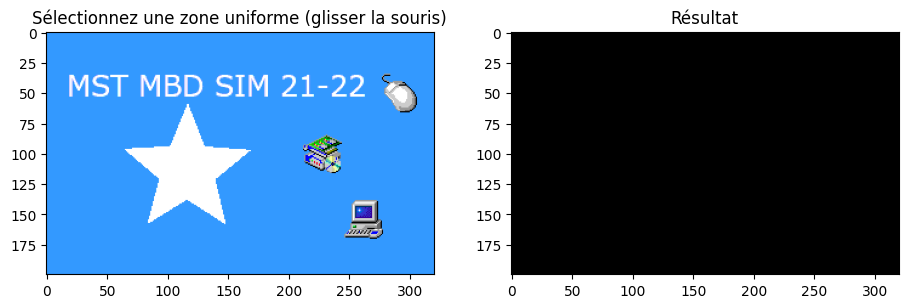

In [8]:
"""
Exercice 1 : l'utilisateur sélectionne une région rectangulaire de couleur uniforme ;
on produit une image où tout pixel dont la couleur diffère de celle de la zone devient noir,
les pixels de couleur similaire restent intacts.
"""
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import RectangleSelector
from pcx_reader import lire_pcx


def couleur_region(img, x0, y0, x1, y1):
    """Couleur représentative de la zone : médiane par canal (robuste au bruit)."""
    zone = img[y0:y1, x0:x1].reshape(-1, 3)
    return np.median(zone, axis=0)


def filtrer_couleur(img, couleur_ref, tolerance=30.0):
    """Garde les pixels dont la distance euclidienne RGB à couleur_ref <= tolerance,
    met les autres à (0,0,0)."""
    dist = np.linalg.norm(img.astype(float) - couleur_ref.astype(float), axis=2)
    masque = dist <= tolerance
    resultat = np.zeros_like(img)
    resultat[masque] = img[masque]
    return resultat


def appliquer(img, x0, y0, x1, y1, tolerance):
    ref = couleur_region(img, x0, y0, x1, y1)
    print(f"Zone ({x0},{y0})-({x1},{y1}) -> couleur de référence RGB = {ref.astype(int)}")
    return filtrer_couleur(img, ref, tolerance)


def interactif(img, tolerance):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
    ax1.imshow(img); ax1.set_title("Sélectionnez une zone uniforme (glisser la souris)")
    ax2.imshow(np.zeros_like(img)); ax2.set_title("Résultat")

    def on_select(eclick, erelease):
        x0, x1 = sorted((int(eclick.xdata), int(erelease.xdata)))
        y0, y1 = sorted((int(eclick.ydata), int(erelease.ydata)))
        if x1 - x0 < 1 or y1 - y0 < 1:
            return
        res = appliquer(img, x0, y0, x1, y1, tolerance)
        ax2.imshow(res); ax2.set_title("Résultat (tolérance = %g)" % tolerance)
        fig.canvas.draw_idle()
        plt.imsave("resultat.png", res)

    fig._sel = RectangleSelector(ax1, on_select, useblit=True, button=[1], interactive=True)
    plt.show()


if __name__ == "__main__":
    image = lire_pcx("Ex2.pcx")
    tol = 30.0
    if len(sys.argv) == 5:       # mode non interactif : x0 y0 x1 y1
        x0, y0, x1, y1 = map(int, sys.argv[1:5])
        res = appliquer(image, x0, y0, x1, y1, tol)
        plt.imsave("resultat.png", res)
    else:
        interactif(image, tol)


PCX v5 : 320x200, RLE=1, 8 bits/pixel, 320 octets/ligne


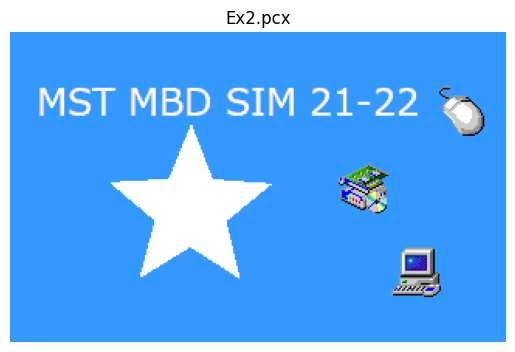

In [9]:
"""
Lecture personnalisée d'un fichier PCX (8 bits/pixel, 1 plan, RLE, palette 256 couleurs)
et affichage avec matplotlib. Aucune bibliothèque d'image (PIL) n'est utilisée pour le décodage.
"""
import struct
import numpy as np
import matplotlib.pyplot as plt


def lire_pcx(chemin):
    with open(chemin, "rb") as f:
        data = f.read()

    # ---------- HEADER (128 bytes) ----------
    fabricant = data[0]
    version = data[1]
    compression = data[2]              # 1 = RLE, 0 = non
    bits_par_pixel = data[3]
    xmin, ymin, xmax, ymax = struct.unpack("<4H", data[4:12])
    nb_plans = data[65]
    octets_par_ligne = struct.unpack("<H", data[66:68])[0]

    if fabricant != 10:
        raise ValueError("Ce n'est pas un fichier PCX (fabricant != 10)")
    if bits_par_pixel != 8 or nb_plans != 1:
        raise NotImplementedError("Seul le PCX 256 couleurs (8 bits, 1 plan) est géré")

    largeur = xmax - xmin + 1
    hauteur = ymax - ymin + 1
    print(f"PCX v{version} : {largeur}x{hauteur}, RLE={compression}, "
          f"{bits_par_pixel} bits/pixel, {octets_par_ligne} octets/ligne")

    # ---------- PALETTE : 768 bytes (256 x RGB) à la fin du fichier ----------
    # Elle est précédée d'un byte marqueur (12 dans la spécification officielle ;
    # l'énoncé indique 192, on accepte donc les deux).
    marqueur = data[-769]
    if marqueur not in (12, 192):
        raise ValueError(f"Marqueur de palette inattendu : {marqueur}")
    pal = np.frombuffer(data[-768:], dtype=np.uint8).reshape(256, 3)  # ordre R,G,B

    # ---------- RASTER (décompression RLE) ----------
    raster_fin = len(data) - 769
    total = octets_par_ligne * hauteur
    pixels = bytearray()
    i = 128
    if compression == 1:
        while len(pixels) < total and i < raster_fin:
            b = data[i]
            i += 1
            if b >= 192:                       # 193..255 (et 192) : octet de répétition
                n = b - 192
                pixels.extend(bytes([data[i]]) * n)
                i += 1
            else:                              # valeur simple
                pixels.append(b)
    else:
        pixels.extend(data[128:128 + total])

    img_index = np.frombuffer(bytes(pixels[:total]), dtype=np.uint8)
    img_index = img_index.reshape(hauteur, octets_par_ligne)[:, :largeur]

    # Conversion indices -> RGB via la palette
    img_rgb = pal[img_index]                   # (hauteur, largeur, 3)
    return img_rgb


if __name__ == "__main__":
    image = lire_pcx("Ex2.pcx")
    plt.imshow(image)
    plt.title("Ex2.pcx")
    plt.axis("off")
    plt.show()
